In [56]:
import pandas as pd
from sodapy import Socrata

# Unauthenticated client only works with public data sets. Note 'None'
# in place of application token, and no username or password:
#client = Socrata("data.transportation.gov", None)

client = Socrata( "data.transportation.gov",
                     '1hCte9vYL7IpE7pFTGR1cbn8y',
                     username="hugo.baca4515@coyote.csusb.edu",
                     password="Hugobacaalex1!" )

# First 2000 results, returned as JSON from API / converted to Python list of
# dictionaries by sodapy.
results = client.get_all("7wn6-i5b9", year='2023')

# Convert to pandas DataFrame
Raw_2023 = pd.DataFrame.from_records(results)

#let's see what we get back
print(Raw_2023)


     railroadcode                        railroadname  year incidentnumber  \
0             ARR         Alaska Railroad Corporation  2023        2023086   
1             ARR         Alaska Railroad Corporation  2023        2023111   
2            BNSF                BNSF Railway Company  2023      CA0223201   
3             FEC  Florida East Coast Railway Company  2023      X31071323   
4             FEC  Florida East Coast Railway Company  2023      X32072623   
...           ...                                 ...   ...            ...   
1363          CSX                  CSX Transportation  2023      000212582   
1364          CSX                  CSX Transportation  2023      000212837   
1365          CSX                  CSX Transportation  2023      000212120   
1366          CSX                  CSX Transportation  2023      000212966   
1367           UP      Union Pacific Railroad Company  2023      0123RM025   

     incidentyear incidentmonth maintenancerailroadcode  \
0   

In [57]:
from numpy.core.fromnumeric import sort

column_headers = list(Raw_2023.columns.values)

column_headers.sort()

print("The Column Headers:")
for header in column_headers:
  print(header)

The Column Headers:
ampm
cityname
countycode
countyname
crossingilluminated
crossingusersinjured
crossinguserskilled
crossingwarning
crossingwarningcode
crossingwarningexpanded1
crossingwarningexpanded2
crossingwarningexpanded3
crossingwarningexpanded4
crossingwarningexpanded5
crossingwarningexpanded6
crossingwarningexpanded7
crossingwarningexpandedcode1
crossingwarningexpandedcode2
crossingwarningexpandedcode3
crossingwarningexpandedcode4
crossingwarningexpandedcode5
crossingwarningexpandedcode6
crossingwarningexpandedcode7
crossingwarningexplanation
crossingwarningexplanationcode
crossingwarninglocation
crossingwarninglocationcode
date
day
district
drivercondition
driverconditioncode
driverinvehicle
driverpassedvehicle
employeesinjured
employeeskilled
equipmentinvolved
equipmentinvolvedcode
equipmentstruck
equipmentstruckcode
equipmenttype
equipmenttypecode
estimatedrecordedspeedcode
estimatedvehiclespeed
form54filed
gradecrossingid
hazmatinvolvement
hazmatinvolvementcode
hazmatrelea

In [58]:
from numpy import NaN
dictionary_data_raw = pd.read_excel('../Data_Dictionaries/Form_54_Data_Dictionary.xlsx')

dictionary = pd.DataFrame.from_records(dictionary_data_raw)

dictionary.columns.values

dictionary = dictionary.filter(items=['Display Name', 'Description'])

print(dictionary)

                Display Name  \
0    Reporting Railroad Code   
1    Reporting Railroad Name   
2                       Year   
3            Accident Number   
4                   PDF Link   
..                       ...   
168                      NaN   
169                      NaN   
170                      NaN   
171                      NaN   
172                      NaN   

                                           Description  
0    Code of the reporting railroad [Block #1a on F...  
1    Name of the reporting railroad [Block #1 on Fo...  
2                                         Report year   
3    Assigned accident number for the reporting rai...  
4                                     PDF link to form  
..                                                 ...  
168                                                NaN  
169                                                NaN  
170                                                NaN  
171                                          

In [59]:
# Create a dictionary to store the corresponding names and descriptions
name_to_description = {}
for index, row in dictionary.iterrows():
    name_to_description[row['Display Name']] = row['Description']

# Get the description for the variable 'report year'
description = name_to_description['Year']
print(description)

#Personal Prefence: Allows me to quickly pull descriptions for variable.

Report year 


In [60]:
#i would like to break up data into smaller chunks to make it easier to work with
# such as by 10 years

print(Raw_2023['year'].max())
print(Raw_2023['year'].min())




2023
2023


In [61]:

from tabulate import tabulate
print(tabulate(Raw_2023, headers = 'keys', tablefmt = 'psql'))


+------+----------------+------------------------------------------------------------+--------+------------------+----------------+-----------------+---------------------------+------------------------------------------------------------+--------------------------------+---------------------------+----------------------------+-------------------+-------------------------+---------+-------+--------+----------+--------+----------+----------------------+----------------------+--------------+---------------------+-------------+----------------+----------------------+----------------------+---------------------+-----------------+-------------------+---------------------+-------------------------+------------------------+--------------------+---------------------------+--------------------------------+-------------------------+------------------------+---------------------------+-----------------------+---------------------------------------+-------------------------+---------------------+--

In [62]:
#Explore for NA's, missing data, and redunnacy

isnaValues = Raw_2023.isna()
print(isnaValues)

# Check for NA values
missing_values = Raw_2023.isna().sum()

#check for null values
missing_data = Raw_2023.isnull().sum()
print(missing_data)

# Check for missing data
for column in Raw_2023.columns:
    if missing_values[column] > 0:
        print(f"The column {column} has {missing_values[column]} missing values.")

# Check for redundancy
for column in Raw_2023.columns:
    if Raw_2023[column].duplicated().sum() > 0:
        print(f"The column {column} has {Raw_2023[column].duplicated().sum()} duplicate values.")

#lets try to clean up raw data

# Calculate the percentage of missing values in each column
missing_values = Raw_2023.isna().mean()

# Drop columns with more than 30% missing values
drop_list = [column for column in missing_values.index if missing_values[column] > 0.3]

# Drop the columns
Raw_2023_clean = Raw_2023.drop(columns=drop_list)


# Check the shape of the raw data
print(f"The Raw Data Frame has {Raw_2023.shape[0]} rows and {Raw_2023.shape[1]} columns.")
print(f"The clean data freame has a mean of missing: {missing_values}")
print(f"\n The Raw Data Frame has {len(Raw_2023.columns)} labels.")
print(f"\n The Clean Data Frame now has {len(Raw_2023_clean.columns)} labels.")
print("\n Count of labels dropped: \n", len(Raw_2023.columns) - len(Raw_2023_clean.columns) )
print("\n Deleted Labels: \n", drop_list)
print("\n Cleaned Data Labels: \n", Raw_2023_clean.columns.values)

      railroadcode  railroadname   year  incidentnumber  incidentyear  \
0            False         False  False           False         False   
1            False         False  False           False         False   
2            False         False  False           False         False   
3            False         False  False           False         False   
4            False         False  False           False         False   
...            ...           ...    ...             ...           ...   
1363         False         False  False           False         False   
1364         False         False  False           False         False   
1365         False         False  False           False         False   
1366         False         False  False           False         False   
1367         False         False  False           False         False   

      incidentmonth  maintenancerailroadcode  maintenancerailroadname  \
0             False                    False      

In [63]:

from tabulate import tabulate
print(tabulate(Raw_2023_clean, headers = 'keys', tablefmt = 'psql'))


+------+----------------+------------------------------------------------------------+--------+------------------+----------------+-----------------+---------------------------+------------------------------------------------------------+--------------------------------+---------------------------+----------------------------+-------------------+-------------------------+---------+-------+--------+----------+--------+----------+----------------------+----------------------+--------------+---------------------+-------------+----------------+----------------------+----------------------+---------------------+-----------------+-------------------+---------------------+-------------------------+------------------------+--------------------+---------------------------+--------------------------------+-------------------------+------------------------+---------------------------+-----------------------+---------------------------------------+-------------------------+---------------------+--

In [64]:
Raw_2023_clean.columns = Raw_2023_clean.columns.str.strip()


In [65]:
columns_to_drop = [
    'railroadcode', 'maintenancerailroadcode', 'maintenancerailroadname',
    'neareststation', 'subdivision', 'reporting_parent_railroad_code',
    'maintenance_parent_railroad_name', 'maintenance_railroad_holding_company',
    'url', 'maintenance_parent_railroad_code', 'maintenance_railroad_smt_grouping',
    'reporting_railroad_holding_company', 'reporting_railroad_smt_grouping',
    'reporting_parent_railroad_name'
]

columns_to_drop = [col for col in columns_to_drop if col in Raw_2023_clean.columns]

Raw_2023_clean.drop(columns=columns_to_drop, inplace=True)


In [66]:
print(tabulate(Raw_2023_clean, headers = 'keys', tablefmt = 'psql'))


+------+------------------------------------------------------------+--------+------------------+----------------+-----------------+--------------------------------+---------------------------+----------------------------+-------------------+-------------------------+---------+-------+--------+----------+--------+----------+--------------+---------------------+-------------+----------------+----------------------+----------------------+---------------------+-----------------+-------------------+---------------------+-------------------------+------------------------+--------------------+---------------------------+--------------------------------+-------------------------+------------------------+---------------------------+-----------------------+---------------------------------------+-------------------------+---------------------+------------------------+--------------------+---------------+------------------+--------------+------------------------+--------------------+------------

In [96]:
missing_values_clean = Raw_2023_clean.isna().mean()


In [97]:
print(missing_values_clean)

railroadname                  0.000000
year                          0.000000
incidentnumber                0.000000
incidentyear                  0.000000
incidentmonth                 0.000000
                                ...   
totalinjuredform55a           0.000000
district                      0.000000
reportkey                     0.000000
reporting_railroad_class      0.146199
maintenance_railroad_class    0.078947
Length: 101, dtype: float64


COOK                32
HARRIS              26
LOS ANGELES         23
BROWARD             19
FULTON              19
SHELBY              17
JEFFERSON           16
PALM BEACH          15
MARION              14
MONTGOMERY          13
WAYNE               12
JACKSON             11
MARICOPA            10
MIAMI-DADE          10
ALAMEDA              9
BUTLER               9
POLK                 9
SUFFOLK              9
ALLEN                9
EAST BATON ROUGE     8
Name: countyname, dtype: int64


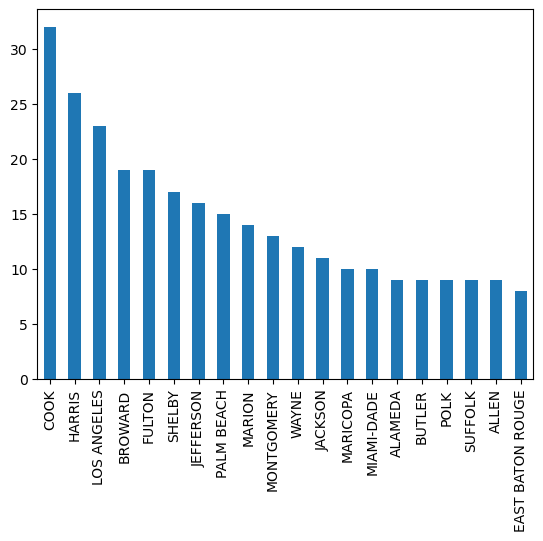

In [94]:
#lets see which county experiences the most accidents
# so basically get a graph x = county, y = number of accidents, all rows in this set are accidents
#get indivial counties and keep track of how many times they appear
import matplotlib.pyplot as plt
import numpy as np
incidentsbycounties = Raw_2023_clean['countyname'].value_counts()
#get the top 10 counties
incidentsbycounties = incidentsbycounties[:20,]
np.savez('../2023incidentsbycounties.npz', incidentsbycounties.to_numpy())
print(incidentsbycounties)
incidentsbycounties.plot.bar()
plt.show()


Quantity of unique counties: 570
+-----+---------------------+---------------------+
|     | countyname          |   totalkilledform57 |
|-----+---------------------+---------------------|
|   0 | ADA                 |                   1 |
|   1 | ADAIR               |                   1 |
|   2 | ADAMS               |                   1 |
|   3 | AIKEN               |                   0 |
|   4 | ALAMEDA             |                   1 |
|   5 | ALLEGAN             |                   1 |
|   6 | ALLEGHENY           |                   0 |
|   7 | ALLEN               |                   0 |
|   8 | ARKANSAS            |                   0 |
|   9 | AROOSTOOK           |                   0 |
|  10 | ASCENSION           |                   0 |
|  11 | ASHTABULA           |                   0 |
|  12 | ATASCOSA            |                   0 |
|  13 | AUSTIN              |                   0 |
|  14 | AUTAUGA             |                   0 |
|  15 | BACA                |  

<Figure size 1400x700 with 0 Axes>

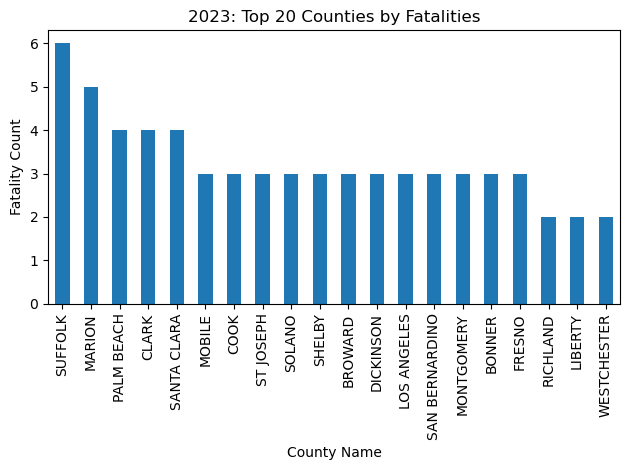

In [69]:
import matplotlib.pyplot as plt
from tabulate import tabulate

# 1. Calculate the number of unique counties
county_count = Raw_2023_clean['countyname'].nunique()
print("Quantity of unique counties:", county_count)
Raw_2023_clean['totalkilledform57'] = pd.to_numeric(Raw_2023_clean['totalkilledform57'], errors='coerce')

# 2. Sum of 'totalkilledform57' grouped by 'countyname'
result_df = Raw_2023_clean.groupby('countyname')['totalkilledform57'].sum().reset_index()
print(tabulate(result_df, headers='keys', tablefmt='psql'))

# 3. Display top 10 counties with the most deaths
print(result_df.sort_values(by='totalkilledform57', ascending=False).head(10))

# 4. Plot top 20 counties by fatalities
top20countiesbyfatalities = result_df.sort_values(by='totalkilledform57', ascending=False).head(20)

plt.figure(figsize=(14, 7))
top20countiesbyfatalities.plot.bar(x='countyname', y='totalkilledform57', legend=False)
plt.title('2023: Top 20 Counties by Fatalities')
plt.xlabel(str('County Name'))
plt.ylabel('Fatality Count')
plt.tight_layout()
plt.show()

np.savez('../2023top20countiesbyfatalities.npz', top20countiesbyfatalities.to_numpy())

In [70]:
print(Raw_2023_clean.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1368 entries, 0 to 1367
Columns: 101 entries, railroadname to maintenance_railroad_class
dtypes: int64(1), object(100)
memory usage: 1.1+ MB
None


025422P    4
050330S    3
631785D    3
725759B    3
637728K    3
718062K    3
676300G    3
025430G    3
153762C    2
723692P    2
510017L    2
916933L    2
028442L    2
819330X    2
628146G    2
766163B    2
348506D    2
053938J    2
272640A    2
524223P    2
Name: gradecrossingid, dtype: int64


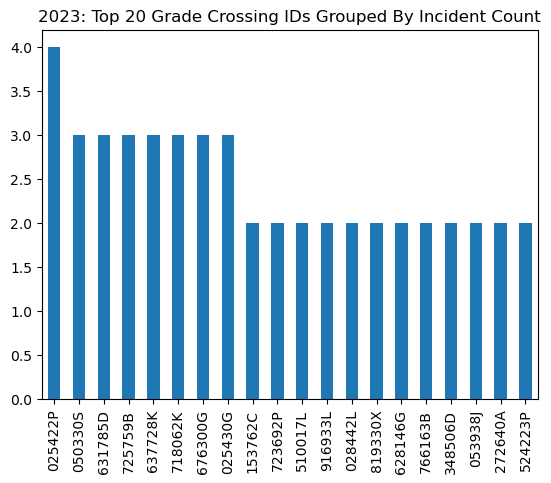

   countyname gradecrossingid  count
0         ADA         819330X      2
1         ADA         819326H      1
2       ADAIR         330391G      1
3       ADAIR         330625H      1
4       ADAMS         070779Y      1
5       ADAMS         072813K      1
6       ADAMS         083178C      1
7       ADAMS         804419H      1
8       ADAMS         804434K      1
9       AIKEN         715767R      1
10    ALAMEDA         749712Y      2
11    ALAMEDA         749634U      1
12    ALAMEDA         749709R      1
13    ALAMEDA         749728V      1
14    ALAMEDA         749774W      1
15    ALAMEDA         751041C      1
16    ALAMEDA         751154H      1
17    ALAMEDA         834232U      1
18    ALLEGAN         234677M      1
19    ALLEGAN         234707C      1


In [71]:
GCF = Raw_2023_clean['gradecrossingid'].value_counts()
print(GCF.head(20))

GCF = GCF[:20,]
GCF.plot.bar(x='index', y='count', title='2023: Top 20 Grade Crossing IDs Grouped By Incident Count')
plt.show()
np.savez('../2023top20GradeCrossingFrequency.npz', GCF.to_numpy())
GCFbycounty = Raw_2023_clean.groupby('countyname')['gradecrossingid'].value_counts().reset_index(name='count')
print(GCFbycounty.head(20))



In [72]:
topcorssingid = Raw_2023_clean[Raw_2023_clean['gradecrossingid'] == '025422P'].get(['countyname', 'statename'])
print(topcorssingid)


    countyname statename
787   MARICOPA   ARIZONA
796   MARICOPA   ARIZONA
798   MARICOPA   ARIZONA
803   MARICOPA   ARIZONA


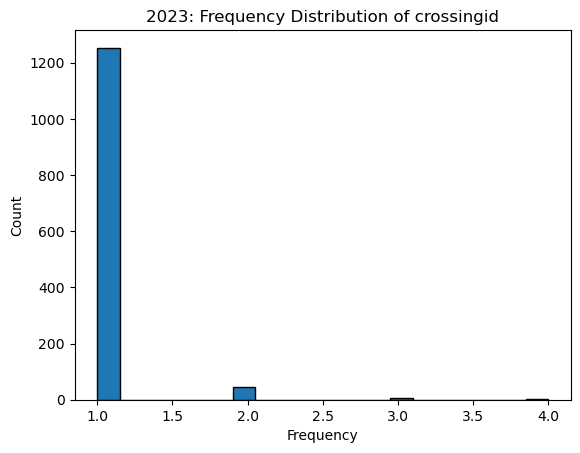

In [73]:
# Assuming you have a DataFrame named df with a 'crossingid' column
# Use value_counts() to get the frequency of each unique crossingid
crossingid_frequency = Raw_2023_clean['gradecrossingid'].value_counts()
#
np.savez('../2023crossingid_frequency.npz', crossingid_frequency.to_numpy() )
# Plot a histogram of the frequencies
plt.hist(crossingid_frequency, bins=20, edgecolor='k')
plt.xlabel('Frequency')
plt.ylabel('Count')
plt.title('2023: Frequency Distribution of crossingid')
plt.show()

/var/folders/8s/cfwx8yqs1h7921qxk7ssn8sm0000gn/T/ipykernel_3662/1778473320.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(crossingid_frequency, kde=True)


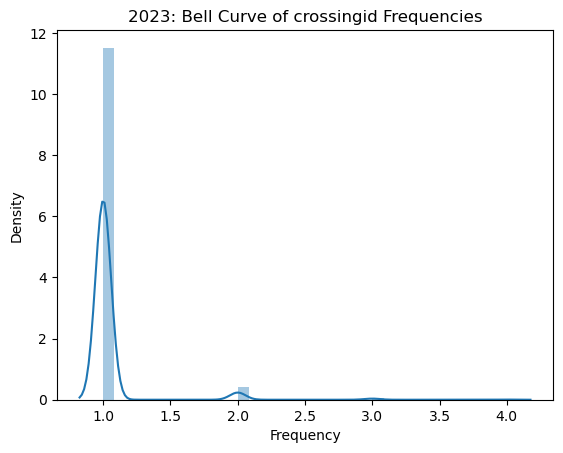

In [95]:
import seaborn as sns

# Assuming you have a DataFrame named df with a 'crossingid' column
# Use value_counts() to get the frequency of each unique crossingid
crossingid_frequency = Raw_2023_clean['gradecrossingid'].value_counts()

# Create a bell curve (normal distribution) plot
sns.distplot(crossingid_frequency, kde=True)
plt.xlabel('Frequency')
plt.ylabel('Density')
plt.title('2023: Bell Curve of crossingid Frequencies')
plt.show()